In [160]:
from hmmlearn import hmm
import pandas as pd
import matplotlib.pyplot as plt

In [161]:
model = hmm.GaussianHMM(n_components=5, covariance_type="full", n_iter=100,random_state=42)
train_df=pd.read_csv('train_df.csv')
train_df=train_df.drop(columns=["Unnamed: 0"])
model.fit(train_df)

,n_components,5
,covariance_type,'full'
,random_state,42
,n_iter,100
,min_covar,0.001
,startprob_prior,1.0
,transmat_prior,1.0
,means_prior,0
,means_weight,0
,covars_prior,0.01
,covars_weight,1


In [162]:
print(train_df.shape, train_df.columns.tolist())
print(train_df.head())

(3706, 4) ['daily_returns', 'sign_persistence', 'rolling_volatility', 'trend']
   daily_returns  sign_persistence  rolling_volatility     trend
0      -0.455275         -0.743581            0.769154  1.620019
1      -1.058761         -0.278561            0.796237  1.430789
2       0.191674         -0.278561            0.790002  1.243011
3       1.626112          0.186459            0.903506  1.104814
4       1.262184          0.651479            0.941577  0.967679


In [163]:
states = model.predict(train_df)
print(pd.Series(states).value_counts().sort_index())

0    1225
1     883
2     751
3     313
4     534
Name: count, dtype: int64


In [164]:
state_analysis = train_df.copy()
state_analysis["state"] = states

print(state_analysis.groupby("state").mean().round(3))

       daily_returns  sign_persistence  rolling_volatility  trend
state                                                            
0             -0.003             0.149              -0.120  0.130
1             -0.017             0.146              -0.476 -0.123
2              0.018            -0.259              -0.780  0.466
3             -0.023            -0.705               2.167 -1.783
4              0.024             0.195               0.889  0.293


In [165]:
print(state_analysis["state"].value_counts().sort_index())

state
0    1225
1     883
2     751
3     313
4     534
Name: count, dtype: int64


In [166]:
print(pd.Series(
    model.transmat_.diagonal(),
    index=range(model.n_components),
    name="probability_of_staying"
).round(3))

0    0.967
1    0.948
2    0.970
3    0.967
4    0.961
Name: probability_of_staying, dtype: float64


In [167]:
# print(pd.Series(
#     model.transmat_[],
#     index=range(model.n_components),
#     name="transition_from_state_5"
# ).round(3))

In [168]:
s = pd.Series(states)
print(((s == 5) & (s.shift(1) == 5)).sum())

0


In [169]:
%store -r means
%store -r standard_deviations

print(state_analysis.groupby("state")["daily_returns"].mean().mul(standard_deviations["daily_returns"]).add(means["daily_returns"]))

state
0    0.000357
1    0.000166
2    0.000648
3    0.000082
4    0.000734
Name: daily_returns, dtype: float64


In [170]:
print(state_analysis.loc[state_analysis["state"] == 5, "daily_returns"].describe())

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: daily_returns, dtype: float64


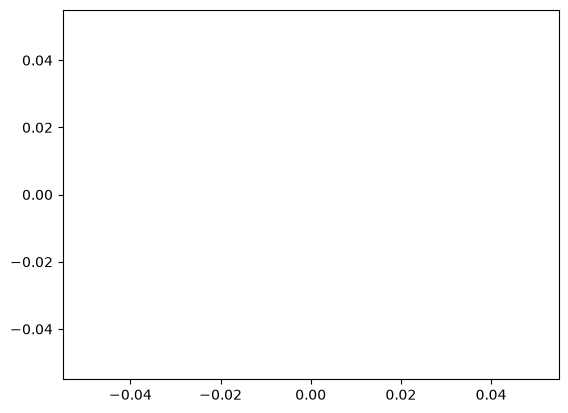

In [171]:
plt.plot(state_analysis[state_analysis["state"] == 5])

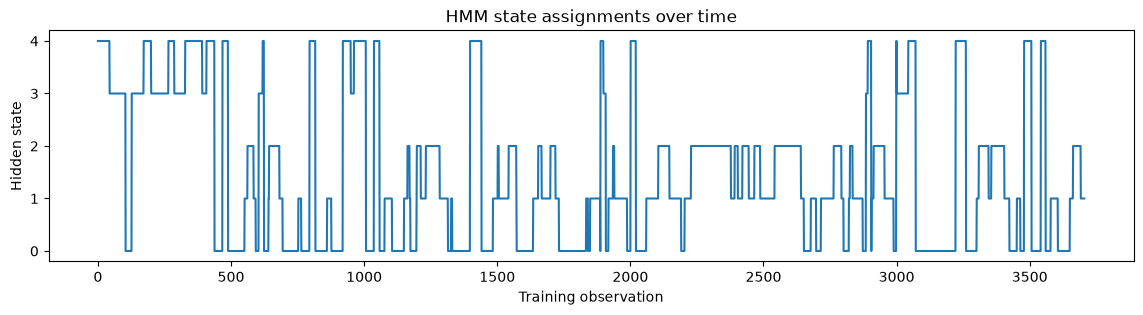

In [172]:
plt.figure(figsize=(14, 3))
plt.plot(states)
plt.xlabel("Training observation")
plt.ylabel("Hidden state")
plt.title("HMM state assignments over time")
plt.show()

In [ ]:
s = pd.Series(states)
groups = s.ne(s.shift()).cumsum()
durations = s.groupby(groups).agg(["first", "size"])
durations.columns = ["state", "duration"]

print(durations.groupby("state")["duration"].agg(["count", "mean", "median", "max"]).round(2))  

       count   mean  median  max
state                           
0         37  33.11    26.0  150
1         45  19.62    16.0   54
2         22  34.14    26.5  150
3         10  31.30    28.5   65
4         20  26.70    25.0   64
